# Rainbow Colormap vs. One-Hue Sequential

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Rainbow colormaps such as jet do not change lightness evenly. They brighten to yellow and cyan and darken at blue and red, so the eye sees sharp "bands" and boundaries that are not in the data, while real gradients get flattened. They also have no intuitive low-to-high order and fail for color-blind readers and in grayscale print.

## When to use

- Use a one-hue sequential map (light = low, dark = high) for continuous magnitude
- Use a two-hue diverging map with a neutral midpoint when the data has a meaningful center

## Avoid when

- Default "jet", "rainbow", "hsv" or "spectral" maps on heatmaps, surfaces and choropleths
- Any map where lightness does not increase monotonically

## Alternatives

- One-hue sequential (Blues, Greens, Oranges)
- Perceptually uniform multi-hue (viridis, cividis) when you need more steps
- Diverging (RdBu) for data around a midpoint

## Design tips

- Check lightness (L*) across the colormap; it should rise or fall monotonically
- Always include a color bar with units
- Test in grayscale; a good sequential map still reads correctly

## Example

A smooth synthetic field (two overlapping Gaussian bumps), like a dose or concentration map.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
x, y = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-2, 2, 200))
z = np.exp(-((x + 0.8) ** 2 + y ** 2)) + 0.7 * np.exp(-((x - 1.3) ** 2 + (y - 0.4) ** 2) / 0.6)


def lightness(cmap, n=256):
    """CIE L* (0 = black, 100 = white) of each color in a colormap."""
    rgb = plt.get_cmap(cmap)(np.linspace(0, 1, n))[:, :3]
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    Y = lin @ np.array([0.2126, 0.7152, 0.0722])
    f = np.where(Y > (6 / 29) ** 3, np.cbrt(Y), Y / (3 * (6 / 29) ** 2) + 4 / 29)
    return 116 * f - 16


pd.Series({"field min": z.min(), "field max": z.max()}).round(3)

field min    0.0
field max    1.0
dtype: float64

### Plot

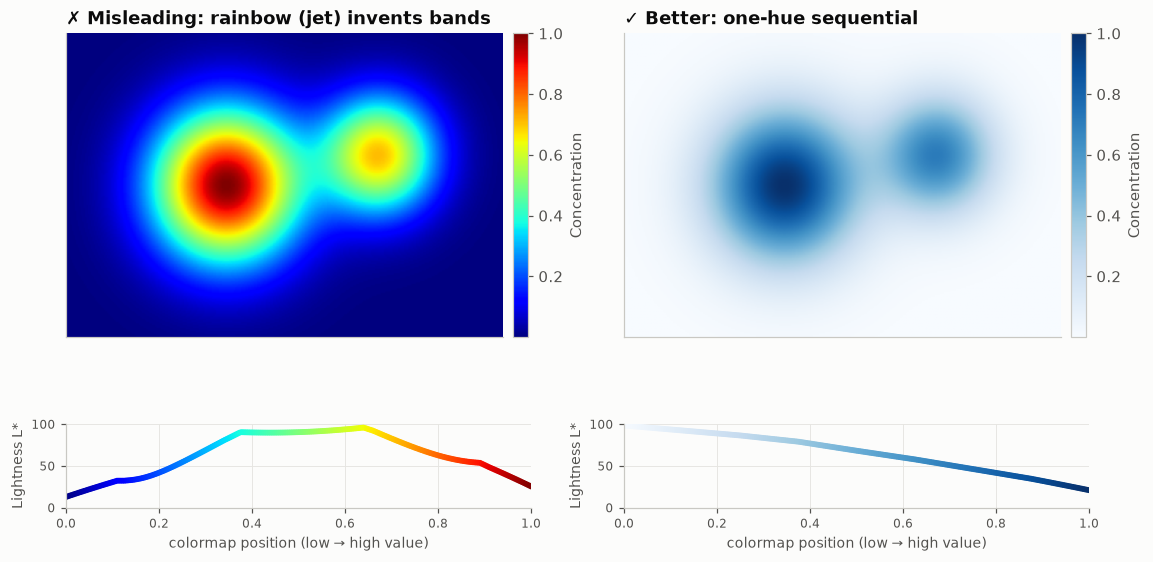

In [3]:
fig = plt.figure(figsize=(12, 5.6))
gs = fig.add_gridspec(2, 2, height_ratios=[4, 1.1], hspace=0.45)
for col, (cmap, title) in enumerate([("jet", "✗ Misleading: rainbow (jet) invents bands"),
                                     (SEQ_CMAP, "✓ Better: one-hue sequential")]):
    ax = fig.add_subplot(gs[0, col])
    im = ax.imshow(z, cmap=cmap, origin="lower", extent=(-3, 3, -2, 2), aspect="auto")
    ax.set_title(title, fontsize=11.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Concentration")
    lax = fig.add_subplot(gs[1, col])
    L = lightness(cmap)
    lax.scatter(np.linspace(0, 1, 256), L, c=np.linspace(0, 1, 256), cmap=cmap, s=8)
    lax.set_ylim(0, 100); lax.set_xlim(0, 1)
    lax.set_ylabel("Lightness L*", fontsize=9)
    lax.set_xlabel("colormap position (low → high value)", fontsize=9)
    lax.tick_params(labelsize=8)
plt.show()

## How to read it

The field is perfectly smooth. Jet draws crisp yellow and cyan rings on the left that are not in the data. The strips below each panel plot the colormap's lightness: jet's goes up and down (false edges), while the one-hue map rises steadily, so it shows the gradient honestly.

---
Standalone script: [`rainbow_colormap.py`](rainbow_colormap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)